In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("AI Data Analyst environment is working!")

AI Data Analyst environment is working!


In [3]:
print("Ready for data exploration!")

Ready for data exploration!


In [4]:
import pandas as pd

file_path = "../data/raw/online_retail_II.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 525461
Columns: 8


In [5]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
df.shape

(525461, 8)

In [7]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


In [9]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(6865)

In [11]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,525461.000000,525461,525461.000000,417534.000000
mean,10.337667,2010-06-28 11:37:36.845018,4.688834,15360.645478
min,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000
25%,1.000000,2010-03-21 12:20:00,1.250000,13983.000000
50%,3.000000,2010-07-06 09:51:00,2.100000,15311.000000
75%,10.000000,2010-10-15 12:45:00,4.210000,16799.000000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000
std,107.424110,NaN,146.126914,1680.811316


In [12]:
negative_quantity = df[df["Quantity"] < 0]

print("Negative quantity rows:", len(negative_quantity))
negative_quantity.head(10)

Negative quantity rows: 12326


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [13]:
negative_quantity["Invoice"].head(20)

178    C489449
179    C489449
180    C489449
181    C489449
182    C489449
183    C489449
184    C489449
185    C489449
186    C489449
196    C489459
197    C489459
198    C489459
199    C489459
200    C489459
201    C489459
202    C489459
203    C489459
204    C489459
205    C489459
206    C489459
Name: Invoice, dtype: object

In [14]:
negative_price = df[df["Price"] < 0]

print("Negative price rows:", len(negative_price))
negative_price.head(10)

Negative price rows: 3


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom


In [15]:
negative_quantity["Invoice"].str.startswith("C").value_counts()

Invoice
True    10205
Name: count, dtype: int64

In [16]:
negative_price

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom


In [17]:
cancellation_invoices = df[
    df["Invoice"].astype(str).str.startswith("C")
]

print("Cancellation rows:", len(cancellation_invoices))
print("Cancellation invoices:", cancellation_invoices["Invoice"].nunique())

Cancellation rows: 10206
Cancellation invoices: 4592


In [18]:
df["Sales"] = df["Quantity"] * df["Price"]
df[["Quantity", "Price", "Sales"]].head()

,Quantity,Price,Sales
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


In [19]:
negative_non_cancellation = negative_quantity[
    ~negative_quantity["Invoice"].astype(str).str.startswith("C")
]

print("Negative quantity without C:", len(negative_non_cancellation))

negative_non_cancellation.head(20)

Negative quantity without C: 2121


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom


In [20]:
negative_non_cancellation["Invoice"].value_counts().head(20)

Invoice
489464    1
489463    1
489467    1
489521    1
489655    1
489660    1
489663    1
489806    1
489820    1
489821    1
489899    1
489901    1
490007    1
490016    1
490055    1
490084    1
490130    1
490146    1
490165    1
490354    1
Name: count, dtype: int64

In [21]:
negative_price

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom


In [22]:
df["Sales"] = df["Quantity"] * df["Price"]

In [23]:
# Create a clean copy
df_clean = df.copy()

# Remove cancellation/return transactions
df_clean = df_clean[df_clean["Quantity"] > 0]

# Remove records with zero or negative prices
df_clean = df_clean[df_clean["Price"] > 0]

print("Original rows:", len(df))
print("Clean rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Original rows: 525461
Clean rows: 511566
Rows removed: 13895


In [24]:
df_clean[["Quantity", "Price", "Sales"]].describe()

,Quantity,Price,Sales
count,511566.000000,511566.000000,511566.000000
mean,11.400150,4.252563,20.146502
std,86.761177,63.664629,90.920077
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,4.200000
50%,3.000000,2.100000,10.140000
75%,10.000000,4.210000,17.700000
max,19152.000000,25111.090000,25111.090000


In [25]:
df_clean.isnull().sum()

Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    103902
Country             0
Sales               0
dtype: int64

In [26]:
df_clean.duplicated().sum()

np.int64(6835)

In [27]:
total_revenue = df_clean["Sales"].sum()
total_units = df_clean["Quantity"].sum()
total_transactions = df_clean["Invoice"].nunique()

print("Total Revenue:", total_revenue)
print("Total Units Sold:", total_units)
print("Total Transactions:", total_transactions)

Total Revenue: 10306265.594
Total Units Sold: 5831929
Total Transactions: 20952


In [28]:
monthly_sales = (
    df_clean
    .set_index("InvoiceDate")
    .resample("ME")["Sales"]
    .sum()
)

monthly_sales

InvoiceDate
2009-12-31     825685.760
2010-01-31     652708.502
2010-02-28     553713.306
2010-03-31     833570.131
2010-04-30     681528.992
2010-05-31     659858.860
2010-06-30     752270.140
2010-07-31     650712.940
2010-08-31     697274.910
2010-09-30     924333.011
2010-10-31    1165483.910
2010-11-30    1470272.482
2010-12-31     438852.650
Freq: ME, Name: Sales, dtype: float64

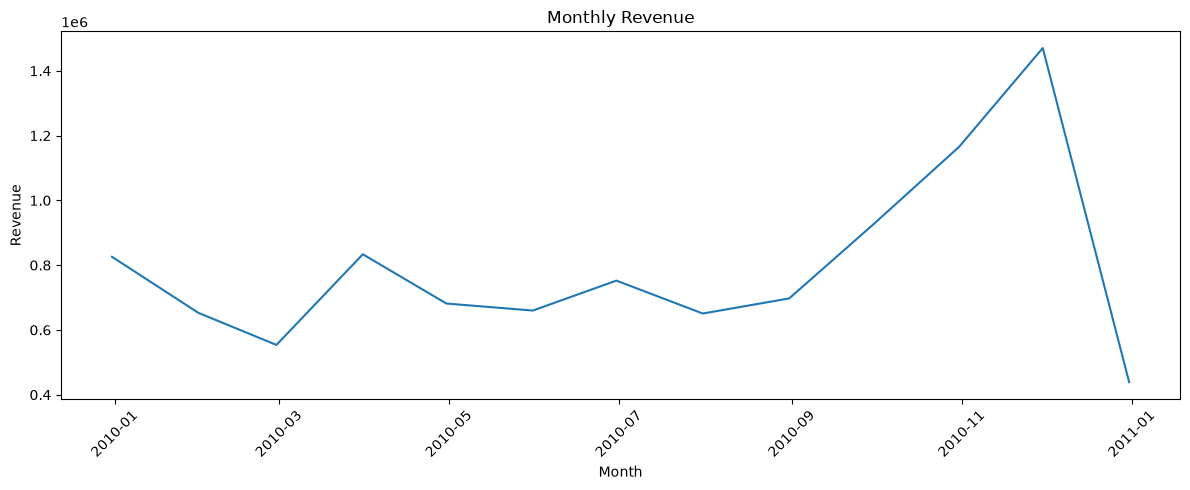

In [29]:
plt.figure(figsize=(12, 5))

plt.plot(monthly_sales.index, monthly_sales.values)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nSummary statistics:")
display(df_clean[["Quantity", "Price", "Sales"]].describe())

Cleaned dataset shape: (511566, 9)

Missing values:
Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    103902
Country             0
Sales               0
dtype: int64

Duplicate rows:
6835

Summary statistics:


,Quantity,Price,Sales
count,511566.000000,511566.000000,511566.000000
mean,11.400150,4.252563,20.146502
std,86.761177,63.664629,90.920077
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,4.200000
50%,3.000000,2.100000,10.140000
75%,10.000000,4.210000,17.700000
max,19152.000000,25111.090000,25111.090000


In [31]:
total_revenue = df_clean["Sales"].sum()
total_units = df_clean["Quantity"].sum()
total_orders = df_clean["Invoice"].nunique()

print("Total Revenue:", total_revenue)
print("Total Units Sold:", total_units)
print("Total Orders:", total_orders)

Total Revenue: 10306265.594
Total Units Sold: 5831929
Total Orders: 20952


In [32]:
monthly_sales = (
    df_clean
    .set_index("InvoiceDate")
    .resample("ME")["Sales"]
    .sum()
)

monthly_sales

InvoiceDate
2009-12-31     825685.760
2010-01-31     652708.502
2010-02-28     553713.306
2010-03-31     833570.131
2010-04-30     681528.992
2010-05-31     659858.860
2010-06-30     752270.140
2010-07-31     650712.940
2010-08-31     697274.910
2010-09-30     924333.011
2010-10-31    1165483.910
2010-11-30    1470272.482
2010-12-31     438852.650
Freq: ME, Name: Sales, dtype: float64

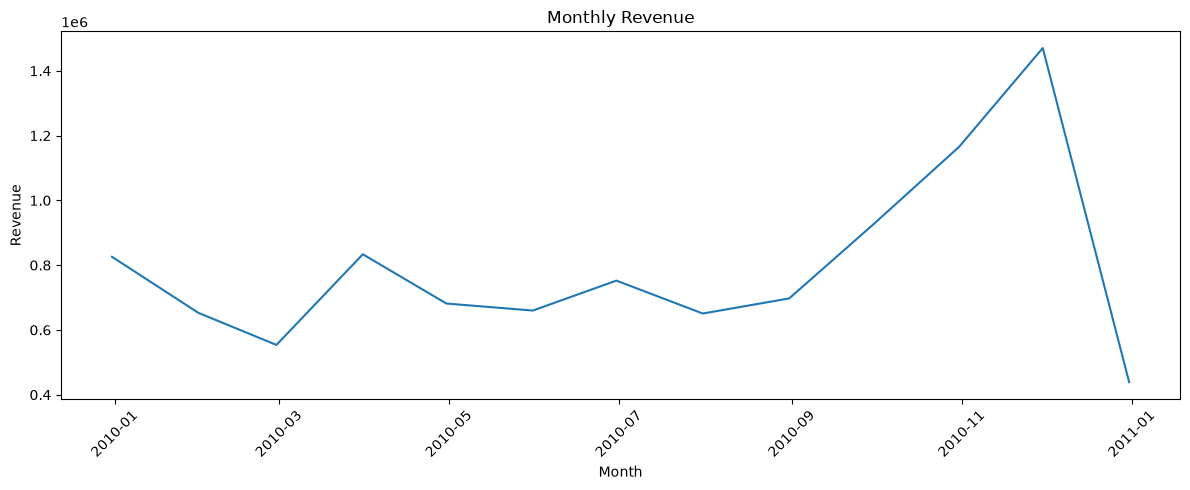

In [33]:
plt.figure(figsize=(12, 5))

plt.plot(monthly_sales.index, monthly_sales.values)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
top_products = (
    df_clean.groupby("Description")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Description
Manual                                 262992.08
REGENCY CAKESTAND 3 TIER               170078.51
WHITE HANGING HEART T-LIGHT HOLDER     160630.78
DOTCOM POSTAGE                         116408.71
ASSORTED COLOUR BIRD ORNAMENT           73092.99
PAPER CHAIN KIT 50'S CHRISTMAS          58189.25
JUMBO BAG RED RETROSPOT                 56595.51
PARTY BUNTING                           49682.72
POSTAGE                                 49477.54
ROTATING SILVER ANGELS T-LIGHT HLDR     47985.09
Name: Sales, dtype: float64

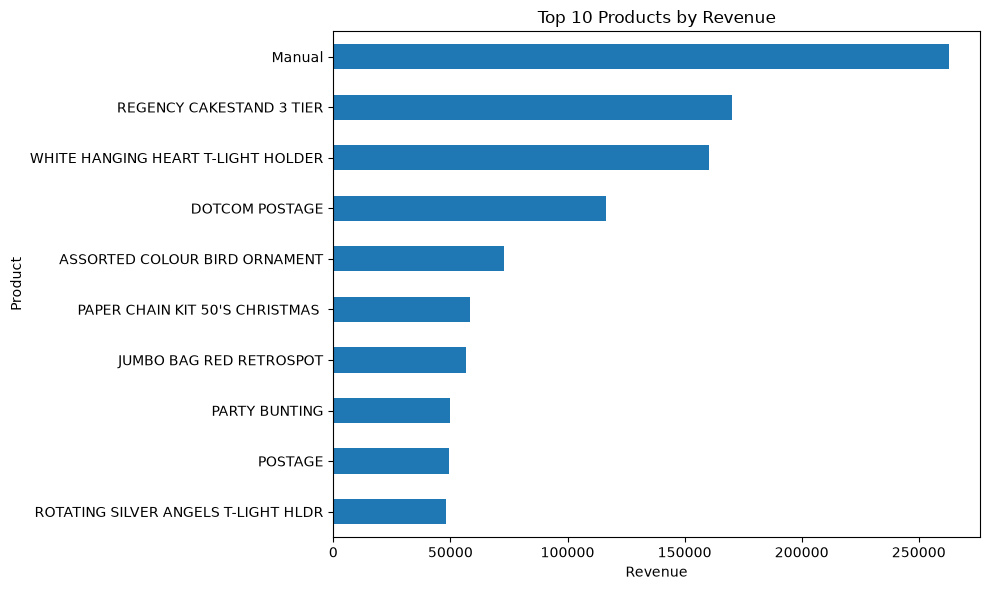

In [35]:
plt.figure(figsize=(10, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [36]:
country_sales = (
    df_clean.groupby("Country")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_sales

Country
United Kingdom    8846129.263
EIRE               380977.820
Netherlands        268786.000
Germany            202395.321
France             147211.490
Sweden              53525.390
Denmark             50906.850
Spain               47601.420
Switzerland         43921.390
Australia           31446.800
Name: Sales, dtype: float64

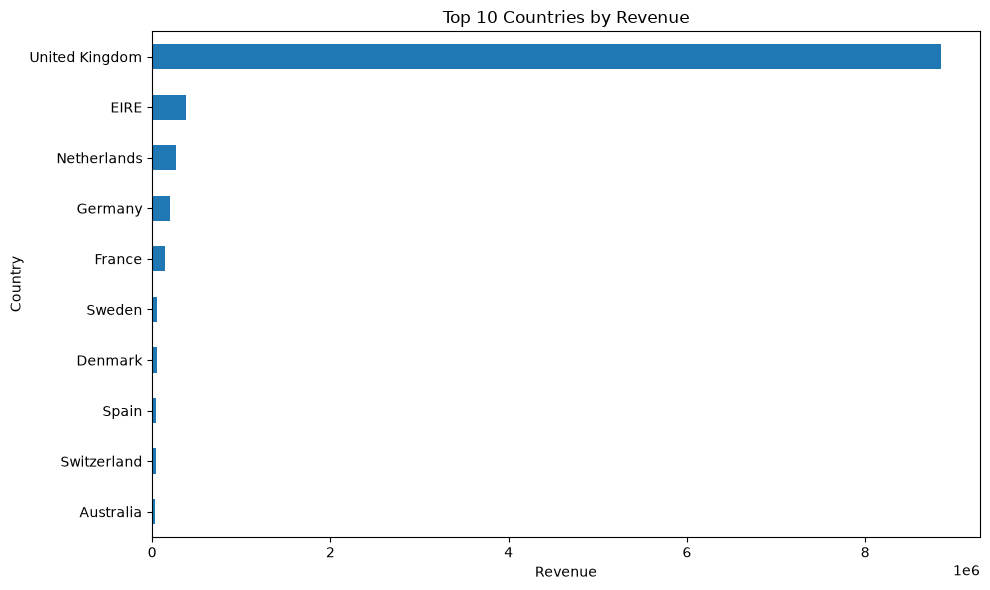

In [37]:
plt.figure(figsize=(10, 6))

country_sales.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [38]:
customer_df = df_clean.dropna(subset=["Customer ID"]).copy()

print("Rows with Customer ID:", len(customer_df))
print("Unique customers:", customer_df["Customer ID"].nunique())

Rows with Customer ID: 407664
Unique customers: 4312


In [39]:
customer_sales = (
    customer_df.groupby("Customer ID")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

customer_sales.head(10)

Customer ID
18102.0    349164.35
14646.0    248396.50
14156.0    196566.74
14911.0    152147.57
13694.0    131443.19
17511.0     84541.17
15061.0     83284.38
16684.0     80489.21
16754.0     65500.07
17949.0     60117.60
Name: Sales, dtype: float64

In [40]:
order_sales = (
    df_clean.groupby("Invoice")["Sales"]
    .sum()
)

average_order_value = order_sales.mean()

print("Average Order Value:", average_order_value)

Average Order Value: 491.8988924207713


In [41]:
customer_sales.describe()

count      4312.000000
mean       2048.238236
std        8914.481280
min           2.950000
25%         307.987500
50%         706.020000
75%        1723.142500
max      349164.350000
Name: Sales, dtype: float64

In [42]:
top_customers = customer_sales.head(10)

top_customers

Customer ID
18102.0    349164.35
14646.0    248396.50
14156.0    196566.74
14911.0    152147.57
13694.0    131443.19
17511.0     84541.17
15061.0     83284.38
16684.0     80489.21
16754.0     65500.07
17949.0     60117.60
Name: Sales, dtype: float64

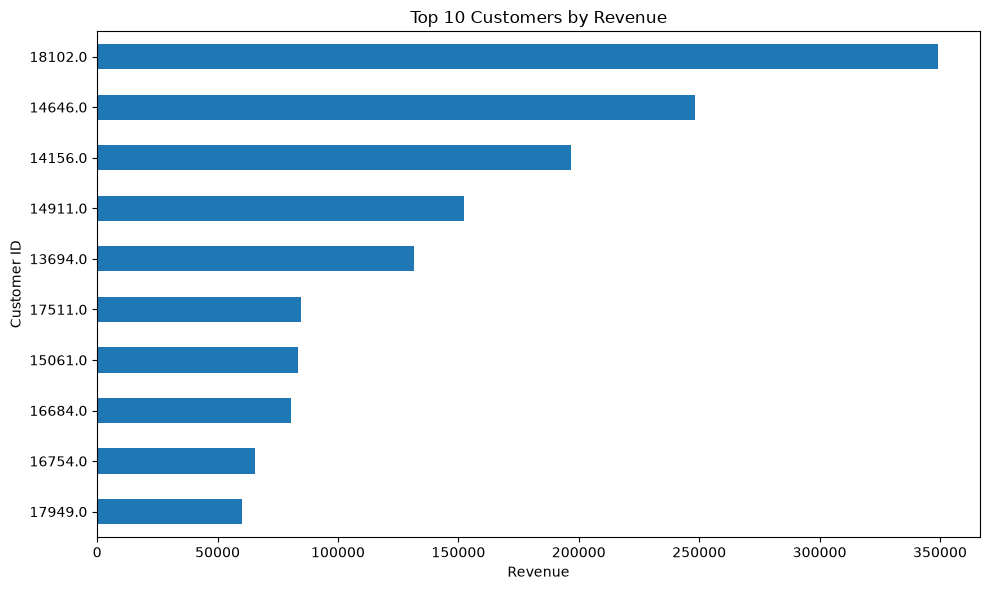

In [43]:
plt.figure(figsize=(10, 6))

top_customers.sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

In [44]:
customer_orders = (
    customer_df.groupby("Customer ID")["Invoice"]
    .nunique()
    .sort_values(ascending=False)
)

customer_orders.head(10)

Customer ID
14911.0    205
17850.0    155
12748.0    144
15311.0    121
13089.0    109
14606.0    102
14156.0    102
13694.0     94
17841.0     91
18102.0     89
Name: Invoice, dtype: int64

In [45]:
kpis = {
    "Total Revenue": df_clean["Sales"].sum(),
    "Total Units Sold": df_clean["Quantity"].sum(),
    "Total Orders": df_clean["Invoice"].nunique(),
    "Average Order Value": df_clean.groupby("Invoice")["Sales"].sum().mean(),
    "Unique Customers": customer_df["Customer ID"].nunique(),
    "Unique Products": df_clean["Description"].nunique(),
    "Countries": df_clean["Country"].nunique()
}

kpis

{'Total Revenue': np.float64(10306265.594),
 'Total Units Sold': np.int64(5831929),
 'Total Orders': 20952,
 'Average Order Value': np.float64(491.8988924207713),
 'Unique Customers': 4312,
 'Unique Products': 4534,
 'Countries': 40}

In [46]:
kpi_df = pd.DataFrame(
    list(kpis.items()),
    columns=["Metric", "Value"]
)

kpi_df

,Metric,Value
0,Total Revenue,1.030627e+07
1,Total Units Sold,5.831929e+06
2,Total Orders,2.095200e+04
3,Average Order Value,4.918989e+02
4,Unique Customers,4.312000e+03
5,Unique Products,4.534000e+03
6,Countries,4.000000e+01


In [48]:
daily_sales = (
    df_clean
    .set_index("InvoiceDate")
    .resample("D")["Sales"]
    .sum()
)

daily_sales.head()

InvoiceDate
2009-12-01    54513.50
2009-12-02    63352.51
2009-12-03    74037.91
2009-12-04    40732.92
2009-12-05     9803.05
Freq: D, Name: Sales, dtype: float64

In [49]:
print("Number of days:", len(daily_sales))
print("Start date:", daily_sales.index.min())
print("End date:", daily_sales.index.max())

Number of days: 374
Start date: 2009-12-01 00:00:00
End date: 2010-12-09 00:00:00


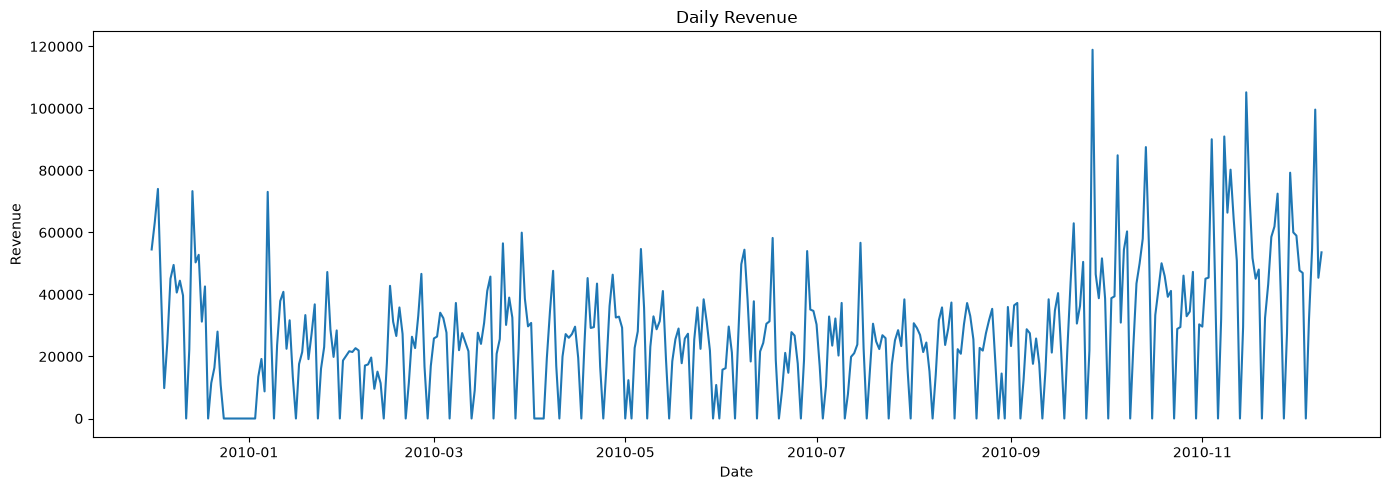

In [50]:
plt.figure(figsize=(14, 5))

plt.plot(daily_sales.index, daily_sales.values)

plt.title("Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

In [51]:
forecast_df = daily_sales.reset_index()

forecast_df.columns = ["Date", "Revenue"]

forecast_df["Day"] = forecast_df["Date"].dt.day
forecast_df["Month"] = forecast_df["Date"].dt.month
forecast_df["Year"] = forecast_df["Date"].dt.year
forecast_df["DayOfWeek"] = forecast_df["Date"].dt.dayofweek

forecast_df.head()

,Date,Revenue,Day,Month,Year,DayOfWeek
0,2009-12-01,54513.50,1,12,2009,1
1,2009-12-02,63352.51,2,12,2009,2
2,2009-12-03,74037.91,3,12,2009,3
3,2009-12-04,40732.92,4,12,2009,4
4,2009-12-05,9803.05,5,12,2009,5


In [52]:
# Use the first 80% for training and the last 20% for testing

split_index = int(len(forecast_df) * 0.8)

train = forecast_df.iloc[:split_index].copy()
test = forecast_df.iloc[split_index:].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))

print("\nTraining period:")
print(train["Date"].min(), "to", train["Date"].max())

print("\nTesting period:")
print(test["Date"].min(), "to", test["Date"].max())

Training rows: 299
Testing rows: 75

Training period:
2009-12-01 00:00:00 to 2010-09-25 00:00:00

Testing period:
2010-09-26 00:00:00 to 2010-12-09 00:00:00


In [53]:
from sklearn.linear_model import LinearRegression

features = ["Day", "Month", "Year", "DayOfWeek"]

X_train = train[features]
y_train = train["Revenue"]

X_test = test[features]
y_test = test["Revenue"]

In [54]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [55]:
predictions = model.predict(X_test)

test["PredictedRevenue"] = predictions

test[["Date", "Revenue", "PredictedRevenue"]].head(10)

,Date,Revenue,PredictedRevenue
299,2010-09-26,21905.72,12722.564374
300,2010-09-27,118909.67,34003.751158
301,2010-09-28,46550.84,30402.013186
302,2010-09-29,38789.98,26800.275213
303,2010-09-30,51641.94,23198.537241
304,2010-10-01,38701.58,21248.640516
305,2010-10-02,0.00,17646.902544
306,2010-10-03,38809.35,14045.164571
307,2010-10-04,39399.48,35326.351356
308,2010-10-05,84879.59,31724.613383


In [56]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 25159.336587533722
RMSE: 30166.806108280056


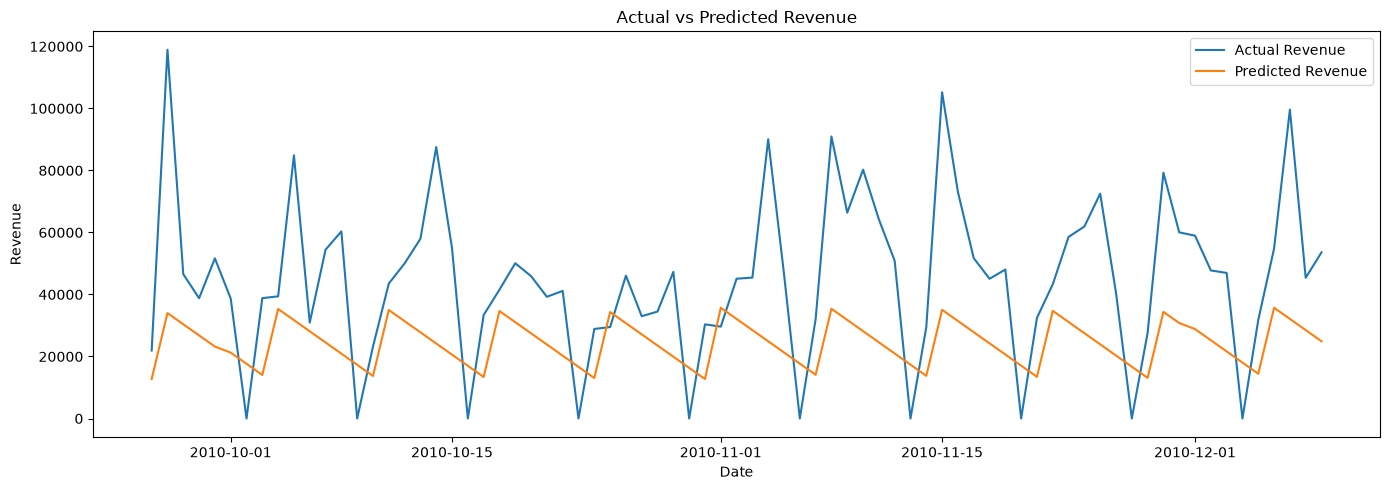

In [57]:
plt.figure(figsize=(14, 5))

plt.plot(test["Date"], test["Revenue"], label="Actual Revenue")
plt.plot(test["Date"], test["PredictedRevenue"], label="Predicted Revenue")

plt.title("Actual vs Predicted Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()

plt.tight_layout()
plt.show()

In [58]:
clean_path = "../data/cleaned_transactions.csv"

df_clean.to_csv(clean_path, index=False)

print("Cleaned dataset saved successfully!")
print("File:", clean_path)

Cleaned dataset saved successfully!
File: ../data/cleaned_transactions.csv
